In [1]:
!pip install -q torch pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import os
import zipfile
import copy
import random
import requests
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [3]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with open("sms_spam.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("sms_spam.zip", "r") as zip_ref:
    zip_ref.extractall("sms_dataset")

file_path = "sms_dataset/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="latin-1"
)

print("Dataset loaded successfully!")
print(df.head())

print("Dataset Shape:", df.shape)

Dataset loaded successfully!
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Dataset Shape: (5572, 2)


In [4]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nStatistical Information:")
print(df.describe(include="all"))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Missing Values:
label      0
message    0
dtype: int64

Duplicate Records:
403

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Statistical Information:
       label                 message
count   5572                    5572
unique     2                    5169
top      ham  Sorry, I'll call later
freq    4825                      30


In [5]:
df.dropna(inplace=True)

df.drop_duplicates(inplace=True)

df["message"] = df["message"].astype(str).str.strip()

df = df[df["message"] != ""]

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df.dropna(subset=["label"], inplace=True)

df["label"] = df["label"].astype(int)

print("Data Cleaning Completed!")
print(df.head())

print("Final Dataset Shape:", df.shape)

Data Cleaning Completed!
   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...
Final Dataset Shape: (5169, 2)


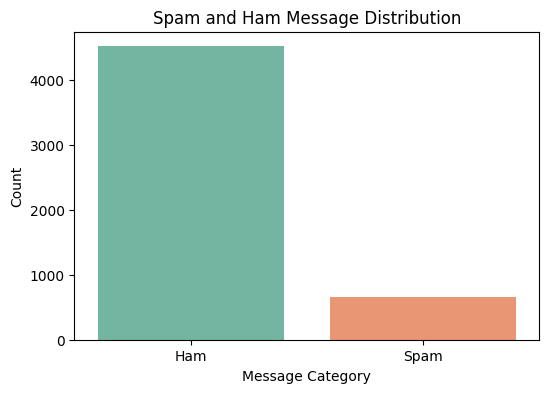

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette="Set2",
    legend=False
)

plt.xticks([0, 1], ["Ham", "Spam"])
plt.title("Spam and Ham Message Distribution")
plt.xlabel("Message Category")
plt.ylabel("Count")

plt.show()

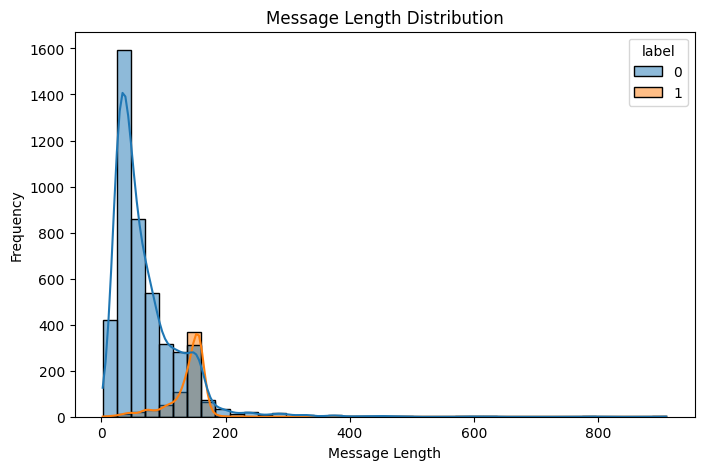

In [7]:
df["message_length"] = df["message"].apply(len)

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=40,
    kde=True
)

plt.title("Message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Frequency")

plt.show()

In [8]:
X = df["message"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

Training Samples: 3618
Validation Samples: 775
Testing Samples: 776


In [9]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_val_tfidf = vectorizer.transform(X_val)

X_test_tfidf = vectorizer.transform(X_test)

print("Training Shape:", X_train_tfidf.shape)
print("Validation Shape:", X_val_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

Training Shape: (3618, 5000)
Validation Shape: (775, 5000)
Testing Shape: (776, 5000)


In [10]:
X_train_array = X_train_tfidf.toarray().astype(np.float32)

X_val_array = X_val_tfidf.toarray().astype(np.float32)

X_test_array = X_test_tfidf.toarray().astype(np.float32)

X_train_tensor = torch.tensor(X_train_array)

X_val_tensor = torch.tensor(X_val_array)

X_test_tensor = torch.tensor(X_test_array)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val.to_numpy(),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
)

print("Tensor Conversion Completed!")

Tensor Conversion Completed!


In [11]:
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("DataLoaders Created Successfully!")

DataLoaders Created Successfully!


In [12]:
class SpamClassifier(nn.Module):

    def __init__(self, input_size):

        super(SpamClassifier, self).__init__()

        self.network = nn.Sequential(

            nn.Linear(input_size, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


input_size = X_train_tensor.shape[1]

model = SpamClassifier(input_size).to(device)

print(model)

SpamClassifier(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [13]:
positive_count = y_train_tensor.sum()

negative_count = len(y_train_tensor) - positive_count

pos_weight = (
    negative_count / positive_count
).to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [14]:
epochs = 30
patience = 5

best_val_loss = float("inf")
counter = 0

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_model_weights = copy.deepcopy(
    model.state_dict()
)

for epoch in range(epochs):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device).view(-1, 1)

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = (outputs >= 0).float()

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    train_loss = running_loss / total

    train_accuracy = correct / total

    # Validation

    model.eval()

    val_running_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in val_loader:

            inputs = inputs.to(device)
            labels = labels.to(device).view(-1, 1)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            val_running_loss += (
                loss.item() * labels.size(0)
            )

            predictions = (outputs >= 0).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_running_loss / val_total

    val_accuracy = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Train Accuracy: {train_accuracy:.4f} "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    # Early Stopping

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_weights = copy.deepcopy(
            model.state_dict()
        )

        counter = 0

    else:

        counter += 1

        if counter >= patience:

            print("Early Stopping Activated!")
            break

model.load_state_dict(best_model_weights)

print("Model Training Completed!")

Epoch [1/30] Train Loss: 0.7088 Val Loss: 0.7718 Train Accuracy: 0.7858 Val Accuracy: 0.8297
Epoch [2/30] Train Loss: 0.2382 Val Loss: 0.2777 Train Accuracy: 0.9776 Val Accuracy: 0.9626
Epoch [3/30] Train Loss: 0.1195 Val Loss: 0.2039 Train Accuracy: 0.9928 Val Accuracy: 0.9652
Epoch [4/30] Train Loss: 0.0686 Val Loss: 0.2107 Train Accuracy: 0.9956 Val Accuracy: 0.9794
Epoch [5/30] Train Loss: 0.0605 Val Loss: 0.1694 Train Accuracy: 0.9936 Val Accuracy: 0.9794
Epoch [6/30] Train Loss: 0.0458 Val Loss: 0.2423 Train Accuracy: 0.9964 Val Accuracy: 0.9819
Epoch [7/30] Train Loss: 0.0352 Val Loss: 0.2016 Train Accuracy: 0.9970 Val Accuracy: 0.9819
Epoch [8/30] Train Loss: 0.0312 Val Loss: 0.2481 Train Accuracy: 0.9975 Val Accuracy: 0.9794
Epoch [9/30] Train Loss: 0.0306 Val Loss: 0.2950 Train Accuracy: 0.9967 Val Accuracy: 0.9742
Epoch [10/30] Train Loss: 0.0435 Val Loss: 0.3289 Train Accuracy: 0.9945 Val Accuracy: 0.9755
Early Stopping Activated!
Model Training Completed!


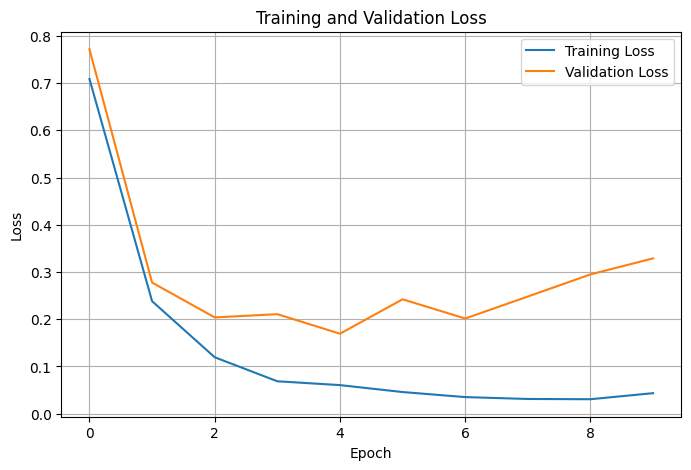

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()

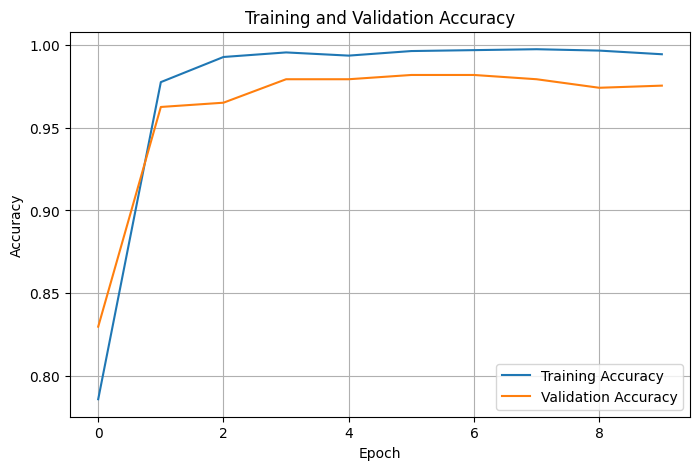

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.show()

In [17]:
model.eval()

all_predictions = []
all_probabilities = []
all_actual = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs)

        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= 0.5
        ).int()

        all_probabilities.extend(
            probabilities.cpu().numpy().flatten()
        )

        all_predictions.extend(
            predictions.cpu().numpy().flatten()
        )

        all_actual.extend(
            labels.numpy().flatten()
        )

all_predictions = np.array(all_predictions)

all_probabilities = np.array(all_probabilities)

all_actual = np.array(all_actual).astype(int)

print("Testing Completed!")

Testing Completed!


In [18]:
accuracy = accuracy_score(
    all_actual,
    all_predictions
)

precision = precision_score(
    all_actual,
    all_predictions,
    zero_division=0
)

recall = recall_score(
    all_actual,
    all_predictions,
    zero_division=0
)

f1 = f1_score(
    all_actual,
    all_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    all_actual,
    all_probabilities
)

print("MODEL EVALUATION RESULTS")

print("-------------------------")

print(f"Accuracy  : {accuracy:.4f}")

print(f"Precision : {precision:.4f}")

print(f"Recall    : {recall:.4f}")

print(f"F1-Score  : {f1:.4f}")

print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        all_actual,
        all_predictions,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

MODEL EVALUATION RESULTS
-------------------------
Accuracy  : 0.9729
Precision : 0.8468
Recall    : 0.9592
F1-Score  : 0.8995
ROC-AUC   : 0.9915

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.97      0.98       678
        Spam       0.85      0.96      0.90        98

    accuracy                           0.97       776
   macro avg       0.92      0.97      0.94       776
weighted avg       0.98      0.97      0.97       776



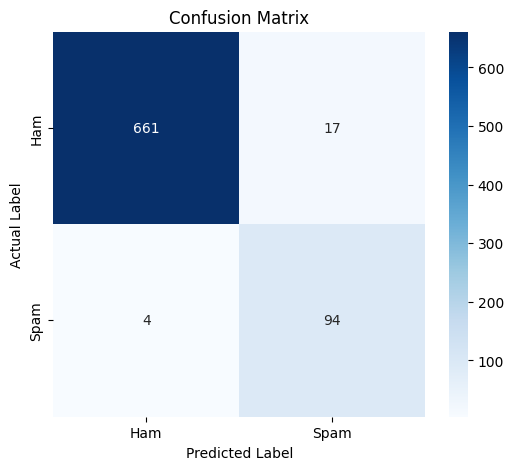

In [19]:
cm = confusion_matrix(
    all_actual,
    all_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.show()

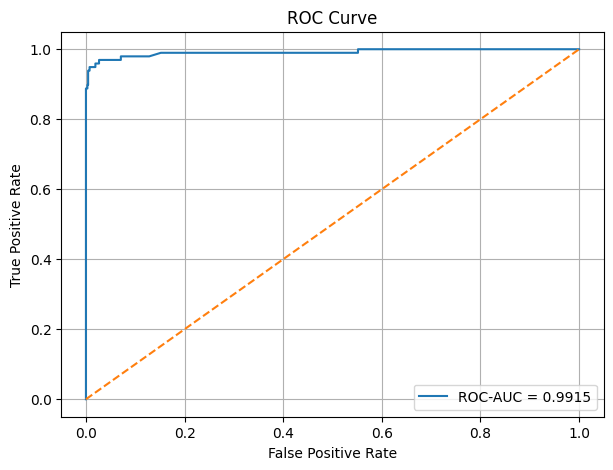

In [20]:
fpr, tpr, thresholds = roc_curve(
    all_actual,
    all_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid()

plt.show()

In [21]:
def predict_message(message):

    model.eval()

    vector = vectorizer.transform([message])

    tensor = torch.tensor(
        vector.toarray().astype(np.float32)
    ).to(device)

    with torch.no_grad():

        output = model(tensor)

        spam_probability = torch.sigmoid(
            output
        ).item()

    ham_probability = 1 - spam_probability

    predicted_class = (
        "SPAM"
        if spam_probability >= 0.5
        else "HAM (NOT SPAM)"
    )

    print("\nSMS MESSAGE:")
    print(message)

    print("\nPREDICTION:", predicted_class)

    print(
        f"Spam Confidence: {spam_probability * 100:.2f}%"
    )

    print(
        f"Ham Confidence: {ham_probability * 100:.2f}%"
    )


predict_message(
    "Congratulations! You have won a free prize. Claim your reward now."
)

predict_message(
    "Hello, how are you? Shall we meet tomorrow?"
)

predict_message(
    "URGENT! You have won a cash prize. Call now to claim."
)

predict_message(
    "Please bring your notebook to class tomorrow."
)


SMS MESSAGE:
Congratulations! You have won a free prize. Claim your reward now.

PREDICTION: SPAM
Spam Confidence: 99.98%
Ham Confidence: 0.02%

SMS MESSAGE:
Hello, how are you? Shall we meet tomorrow?

PREDICTION: HAM (NOT SPAM)
Spam Confidence: 1.85%
Ham Confidence: 98.15%

SMS MESSAGE:
URGENT! You have won a cash prize. Call now to claim.

PREDICTION: SPAM
Spam Confidence: 99.99%
Ham Confidence: 0.01%

SMS MESSAGE:
Please bring your notebook to class tomorrow.

PREDICTION: HAM (NOT SPAM)
Spam Confidence: 1.92%
Ham Confidence: 98.08%


In [22]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_size": input_size
    },
    "sms_spam_model.pth"
)

joblib.dump(
    vectorizer,
    "tfidf_vectorizer.joblib"
)

print("Model Saved Successfully!")

print("1. sms_spam_model.pth")

print("2. tfidf_vectorizer.joblib")

Model Saved Successfully!
1. sms_spam_model.pth
2. tfidf_vectorizer.joblib


In [23]:
from google.colab import files

files.download("sms_spam_model.pth")

files.download("tfidf_vectorizer.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>